In [ ]:
!pip install sahi ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 18.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [ultralytics]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

# Update this to your actual path in Google Drive
BASE_DIR = '/content/drive/MyDrive/YOLO'

MODEL_PATH = os.path.join(BASE_DIR, 'yolov8l.pt')
DATA_YAML = os.path.join(BASE_DIR, 'data.yaml')
VALID_IMAGES = os.path.join(BASE_DIR, 'valid/images')
VALID_LABELS = os.path.join(BASE_DIR, 'valid/labels')

## YOLOv8 and SAHI comparison with visual bounding boxes


Image size: 831x554

Confidence >= 0.25, image 831x554
             Detections  Mean confidence  Max confidence  Classes found  Time (ms)
YOLOv8              2.0            0.288           0.294            1.0     31.547
YOLOv8+SAHI        20.0            0.435           0.816            1.0    151.834

Detections per class (count, mean confidence):
                         YOLOv8     YOLOv8+SAHI
Corn leaf blight  2 (mean 0.29)  20 (mean 0.44)

Saved: /content/drive/MyDrive/YOLO/external_results/side_by_side.png


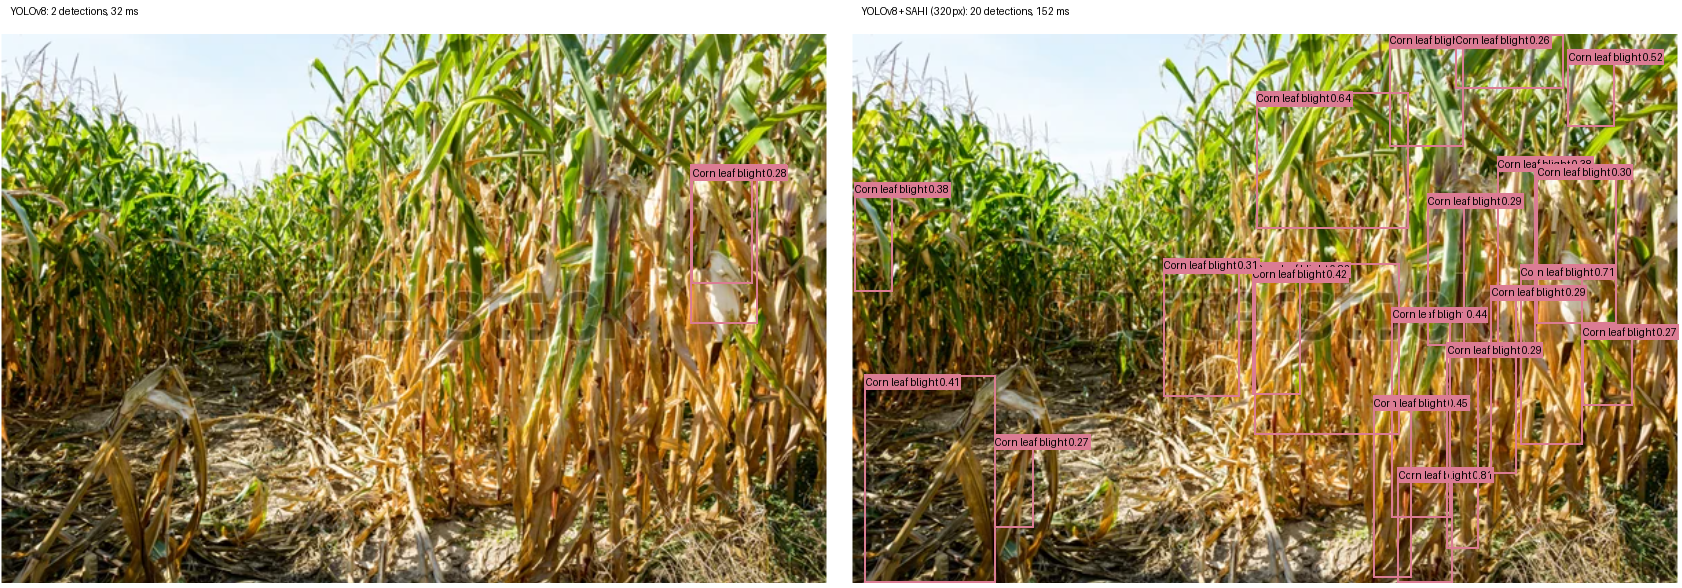

In [ ]:
# Compare YOLOv8 vs YOLOv8+SAHI on an image WITHOUT labels.
# Standalone: only needs your weights path and an image path.
import os, time
import numpy as np, pandas as pd
from PIL import Image, ImageDraw, ImageFont, ImageOps
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# ---------------- CONFIG ----------------
WEIGHTS    = '/content/drive/MyDrive/YOLO/runs/detect/train-4/weights/best.pt'
IMAGE_PATH = '/content/Screenshot 2026-11-18 135416.png'   # <- your image
CONF       = 0.25      # same confidence threshold for both methods
NMS_IOU    = 0.7
IMGSZ      = 224       # the size the model was trained at (used for BOTH methods)
# SAHI slice size in ORIGINAL pixels. Every slice is resized to IMGSZ before the model sees it.
# Since the model learned "one leaf fills the frame", pick a slice about the size of ONE leaf
# in your photo (e.g. leaf ~600 px wide -> slice 640). Try 2-3 values and compare.
SLICE      = 320
OVERLAP    = 0.25
OUT_DIR    = '/content/drive/MyDrive/YOLO/external_results'
os.makedirs(OUT_DIR, exist_ok=True)

# ---------------- load image (fix EXIF rotation once, use same file for both) ----------------
img = ImageOps.exif_transpose(Image.open(IMAGE_PATH)).convert('RGB')
W, H = img.size
tmp_path = os.path.join(OUT_DIR, 'input_oriented.jpg')
img.save(tmp_path, quality=95)
print(f'Image size: {W}x{H}')

model = YOLO(WEIGHTS)
names = model.names
sahi_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics', model_path=WEIGHTS,
    confidence_threshold=CONF, device='cuda:0')
sahi_model.model.overrides['imgsz'] = IMGSZ   # make sure every slice is run at the same size as the baseline


def run_yolo():
    r = model.predict(tmp_path, conf=CONF, iou=NMS_IOU, imgsz=IMGSZ, verbose=False)[0]
    return [(b, float(s), int(c)) for b, s, c in
            zip(r.boxes.xyxy.cpu().tolist(), r.boxes.conf.cpu().tolist(), r.boxes.cls.cpu().tolist())]


def run_sahi():
    res = get_sliced_prediction(
        tmp_path, sahi_model, slice_height=SLICE, slice_width=SLICE,
        overlap_height_ratio=OVERLAP, overlap_width_ratio=OVERLAP,
        perform_standard_pred=True,
        postprocess_type='GREEDYNMM', postprocess_match_metric='IOS',
        postprocess_match_threshold=0.5, verbose=0)
    return [(o.bbox.to_xyxy(), float(o.score.value), int(o.category.id))
            for o in res.object_prediction_list]


def timed(fn, repeats=3):
    fn()                                   # warm-up (first GPU call is slow)
    ts, out = [], None
    for _ in range(repeats):
        t = time.time(); out = fn(); ts.append((time.time() - t) * 1000)
    return out, float(np.mean(ts))


dets_y, ms_y = timed(run_yolo)
dets_s, ms_s = timed(run_sahi, repeats=2)

# ---------------- numbers ----------------
def summarize(dets, ms):
    confs = [d[1] for d in dets]
    return {'Detections': len(dets),
            'Mean confidence': float(np.mean(confs)) if confs else 0.0,
            'Max confidence': float(np.max(confs)) if confs else 0.0,
            'Classes found': len({d[2] for d in dets}),
            'Time (ms)': ms}

summary = pd.DataFrame({'YOLOv8': summarize(dets_y, ms_y),
                        'YOLOv8+SAHI': summarize(dets_s, ms_s)}).T
print(f'\nConfidence >= {CONF}, image {W}x{H}')
print(summary.round(3).to_string())

def per_class(dets):
    out = {}
    for _, s, c in dets:
        out.setdefault(names[c], []).append(s)
    return {k: f'{len(v)} (mean {np.mean(v):.2f})' for k, v in out.items()}

cls_table = pd.DataFrame({'YOLOv8': per_class(dets_y),
                          'YOLOv8+SAHI': per_class(dets_s)}).fillna('0')
print('\nDetections per class (count, mean confidence):')
print(cls_table.to_string())

summary.to_csv(os.path.join(OUT_DIR, 'summary.csv'))
cls_table.to_csv(os.path.join(OUT_DIR, 'per_class.csv'))

# ---------------- side-by-side picture ----------------
def draw(dets, title):
    im = img.copy()
    d = ImageDraw.Draw(im)
    lw = max(2, int(max(W, H) / 400))
    fs = max(12, int(max(W, H) / 70))
    try:
        font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf', fs)
    except Exception:
        font = ImageFont.load_default()
    rng = np.random.default_rng(1)
    palette = {c: tuple(int(x) for x in rng.integers(60, 255, 3)) for c in range(len(names))}
    for (x1, y1, x2, y2), s, c in dets:
        col = palette[c]
        d.rectangle([x1, y1, x2, y2], outline=col, width=lw)
        label = f'{names[c]} {s:.2f}'
        tb = d.textbbox((x1, y1), label, font=font)
        d.rectangle([tb[0], tb[1] - 2, tb[2] + 2, tb[3] + 2], fill=col)
        d.text((x1 + 1, y1), label, fill='black', font=font)
    bar = Image.new('RGB', (W, fs * 2 + 10), 'white')
    ImageDraw.Draw(bar).text((10, 5), title, fill='black', font=font)
    canvas = Image.new('RGB', (W, H + bar.height), 'white')
    canvas.paste(bar, (0, 0)); canvas.paste(im, (0, bar.height))
    return canvas

a = draw(dets_y, f'YOLOv8: {len(dets_y)} detections, {ms_y:.0f} ms')
b = draw(dets_s, f'YOLOv8+SAHI ({SLICE}px): {len(dets_s)} detections, {ms_s:.0f} ms')
side = Image.new('RGB', (a.width + b.width + 20, a.height), 'white')
side.paste(a, (0, 0)); side.paste(b, (a.width + 20, 0))
out_png = os.path.join(OUT_DIR, 'side_by_side.png')
side.save(out_png)
a.save(os.path.join(OUT_DIR, 'yolo_only.png')); b.save(os.path.join(OUT_DIR, 'sahi_only.png'))
print(f'\nSaved: {out_png}')

# display in notebook
try:
    from IPython.display import display
    display(side.resize((min(1800, side.width), int(side.height * min(1800, side.width) / side.width))))
except Exception:
    pass

## YOLO and SAHI comparison on test images
## (includes detections with TP,FP,FN and other metrics)

In [ ]:
# TP / FP / FN for YOLOv8 vs YOLOv8+SAHI on a labeled image folder.
# Standalone. Run in Colab (pip install sahi ultralytics first).
import os, glob, time
import numpy as np, pandas as pd, torch
from PIL import Image, ImageOps
from tqdm import tqdm
from ultralytics import YOLO
from ultralytics.utils.metrics import box_iou
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

# ---------------- CONFIG ----------------
ROOT    = '/content/drive/MyDrive/YOLO'
WEIGHTS = f'{ROOT}/runs/detect/train-4/weights/best.pt'
IMG_DIR = f'{ROOT}/test/images'
LBL_DIR = f'{ROOT}/test/labels'
CONF    = 0.25        # fixed confidence threshold (needed for TP/FP/FN) - same for both
IOU_THR = 0.5         # a prediction is a TP if IoU >= this AND the class matches
NMS_IOU = 0.7
IMGSZ   = 224         # trained size, used for both methods
SLICE, OVERLAP = 512, 0.3          # SAHI settings (full-image pass + GREEDYNMM/IOS)
SMALL_THR, MIN_BOXES = 0.1, 2      # a-priori "small / multi-object" definition
OUT_CSV = 'tp_fp_fn_per_image.csv'

model = YOLO(WEIGHTS)
sahi_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics', model_path=WEIGHTS,
    confidence_threshold=CONF, device='cuda:0')
sahi_model.model.overrides['imgsz'] = IMGSZ


# ---------------- helpers ----------------
def load_gt(img_path):
    w, h = Image.open(img_path).size
    lbl = os.path.join(LBL_DIR, os.path.splitext(os.path.basename(img_path))[0] + '.txt')
    cls, boxes = [], []
    if os.path.exists(lbl):
        for line in open(lbl).read().splitlines():
            v = line.split()
            if len(v) < 5:
                continue
            c, n = int(float(v[0])), list(map(float, v[1:]))
            if len(n) == 4:                                   # box: xc yc w h
                xc, yc, bw, bh = n
                x1, y1, x2, y2 = xc - bw / 2, yc - bh / 2, xc + bw / 2, yc + bh / 2
            else:                                             # polygon -> enclosing box
                xs, ys = n[0::2], n[1::2]
                x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            cls.append(c)
            boxes.append([x1 * w, y1 * h, x2 * w, y2 * h])
    return (torch.tensor(cls, dtype=torch.float32),
            torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), (w, h))


def predict_yolo(p):
    r = model.predict(p, conf=CONF, iou=NMS_IOU, imgsz=IMGSZ, verbose=False)[0]
    return r.boxes.xyxy.cpu(), r.boxes.conf.cpu(), r.boxes.cls.cpu()


def predict_sahi(p):
    res = get_sliced_prediction(
        p, sahi_model, slice_height=SLICE, slice_width=SLICE,
        overlap_height_ratio=OVERLAP, overlap_width_ratio=OVERLAP,
        perform_standard_pred=True,
        postprocess_type='GREEDYNMM', postprocess_match_metric='IOS',
        postprocess_match_threshold=0.5, verbose=0)
    L = [o for o in res.object_prediction_list if o.score.value >= CONF]
    boxes = torch.tensor([o.bbox.to_xyxy() for o in L], dtype=torch.float32).reshape(-1, 4)
    scores = torch.tensor([o.score.value for o in L], dtype=torch.float32)
    cls = torch.tensor([o.category.id for o in L], dtype=torch.float32)
    return boxes, scores, cls


def count_tp_fp_fn(pred, gcls, gbox):
    """Greedy matching by score; class-aware; each GT box can be matched once."""
    boxes, scores, cls = pred
    tp, matched = 0, set()
    if len(boxes) and len(gbox):
        iou = box_iou(gbox, boxes)
        for j in scores.argsort(descending=True).tolist():
            best, best_i = IOU_THR, None
            for i in range(len(gbox)):
                if i in matched or gcls[i] != cls[j]:
                    continue
                if iou[i, j] >= best:
                    best, best_i = float(iou[i, j]), i
            if best_i is not None:
                matched.add(best_i)
                tp += 1
    fp, fn = len(boxes) - tp, len(gbox) - tp
    return tp, fp, fn


def prf(tp, fp, fn):
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    F = 2 * P * R / (P + R) if P + R else 0.0
    return P, R, F


# ---------------- run on every image ----------------
paths = sorted(p for p in glob.glob(f'{IMG_DIR}/*') if p.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')))
rows = []
for p in tqdm(paths):
    gcls, gbox, (w, h) = load_gt(p)
    med = float((((gbox[:, 2] - gbox[:, 0]) * (gbox[:, 3] - gbox[:, 1])) / (w * h)).median()) if len(gbox) else np.nan

    t = time.time(); py = predict_yolo(p); ty = (time.time() - t) * 1000
    t = time.time(); ps = predict_sahi(p); ts = (time.time() - t) * 1000
    tpy, fpy, fny = count_tp_fp_fn(py, gcls, gbox)
    tps, fps, fns = count_tp_fp_fn(ps, gcls, gbox)
    f1y, f1s = prf(tpy, fpy, fny)[2], prf(tps, fps, fns)[2]
    rows.append({'image': os.path.basename(p), 'n_gt': len(gbox), 'median_rel_area': med,
                 'TP_yolo': tpy, 'FP_yolo': fpy, 'FN_yolo': fny, 'F1_yolo': f1y, 'ms_yolo': ty,
                 'TP_sahi': tps, 'FP_sahi': fps, 'FN_sahi': fns, 'F1_sahi': f1s, 'ms_sahi': ts})

df = pd.DataFrame(rows)
df['verdict'] = np.where(df.F1_sahi > df.F1_yolo + 1e-9, 'SAHI better',
                 np.where(df.F1_sahi < df.F1_yolo - 1e-9, 'SAHI worse', 'tie'))
df.to_csv(OUT_CSV, index=False)


# ---------------- aggregate (sum TP/FP/FN over images, then P/R/F1) ----------------
def table(sub, label):
    out = {}
    for m, name in [('yolo', 'YOLOv8'), ('sahi', 'YOLOv8+SAHI')]:
        tp, fp, fn = sub[f'TP_{m}'].sum(), sub[f'FP_{m}'].sum(), sub[f'FN_{m}'].sum()
        P, R, F = prf(tp, fp, fn)
        out[(label, name)] = {'Images': len(sub), 'GT boxes': int(sub.n_gt.sum()),
                              'TP': int(tp), 'FP': int(fp), 'FN': int(fn),
                              'Precision': P, 'Recall': R, 'F1': F,
                              'ms/img': sub[f'ms_{m}'].mean()}
    return out

small = df[(df.n_gt >= MIN_BOXES) & (df.median_rel_area < SMALL_THR)]
groups = {
    'All images': df,
    f'A priori: small/multi-object (median area<{SMALL_THR}, >={MIN_BOXES} boxes)': small,
    'POST HOC: images where SAHI F1 > baseline F1': df[df.verdict == 'SAHI better'],
    'POST HOC: images where SAHI F1 < baseline F1': df[df.verdict == 'SAHI worse'],
    'POST HOC: ties': df[df.verdict == 'tie'],
}
res = {}
for label, sub in groups.items():
    if len(sub):
        res.update(table(sub, label))
out = pd.DataFrame(res).T
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 80)
print(f'\nConf >= {CONF}, IoU >= {IOU_THR}, imgsz {IMGSZ}, SAHI {SLICE}px/overlap {OVERLAP}')
print(out.round(3).to_string())
out.to_csv('tp_fp_fn_summary.csv')

print('\nVerdict counts:\n', df.verdict.value_counts().to_string())
print('\nNOTE: the "POST HOC" rows pick images AFTER seeing which method won, so they overstate SAHI.'
      '\nReport them only as "where SAHI helps", next to the all-images and a-priori rows.')
print(f'Per-image numbers saved to {OUT_CSV}')

100%|██████████| 249/249 [03:05<00:00,  1.34it/s]


Conf >= 0.25, IoU >= 0.5, imgsz 224, SAHI 512px/overlap 0.3
                                                                       Images  GT boxes     TP      FP     FN  Precision  Recall     F1   ms/img
All images                                                YOLOv8        249.0     867.0  530.0   671.0  337.0      0.441   0.611  0.513   34.984
                                                          YOLOv8+SAHI   249.0     867.0  606.0  1491.0  261.0      0.289   0.699  0.409  126.492
A priori: small/multi-object (median area<0.1, >=2 boxes) YOLOv8         88.0     589.0  345.0   453.0  244.0      0.432   0.586  0.497   47.010
                                                          YOLOv8+SAHI    88.0     589.0  402.0   893.0  187.0      0.310   0.683  0.427  126.018
POST HOC: images where SAHI F1 > baseline F1              YOLOv8         42.0     231.0   66.0   227.0  165.0      0.225   0.286  0.252   26.883
                                                          YOLOv8+SAHI

## Slices made by SAHI


Displaying all 12 slices found in 'sahi_slices/':


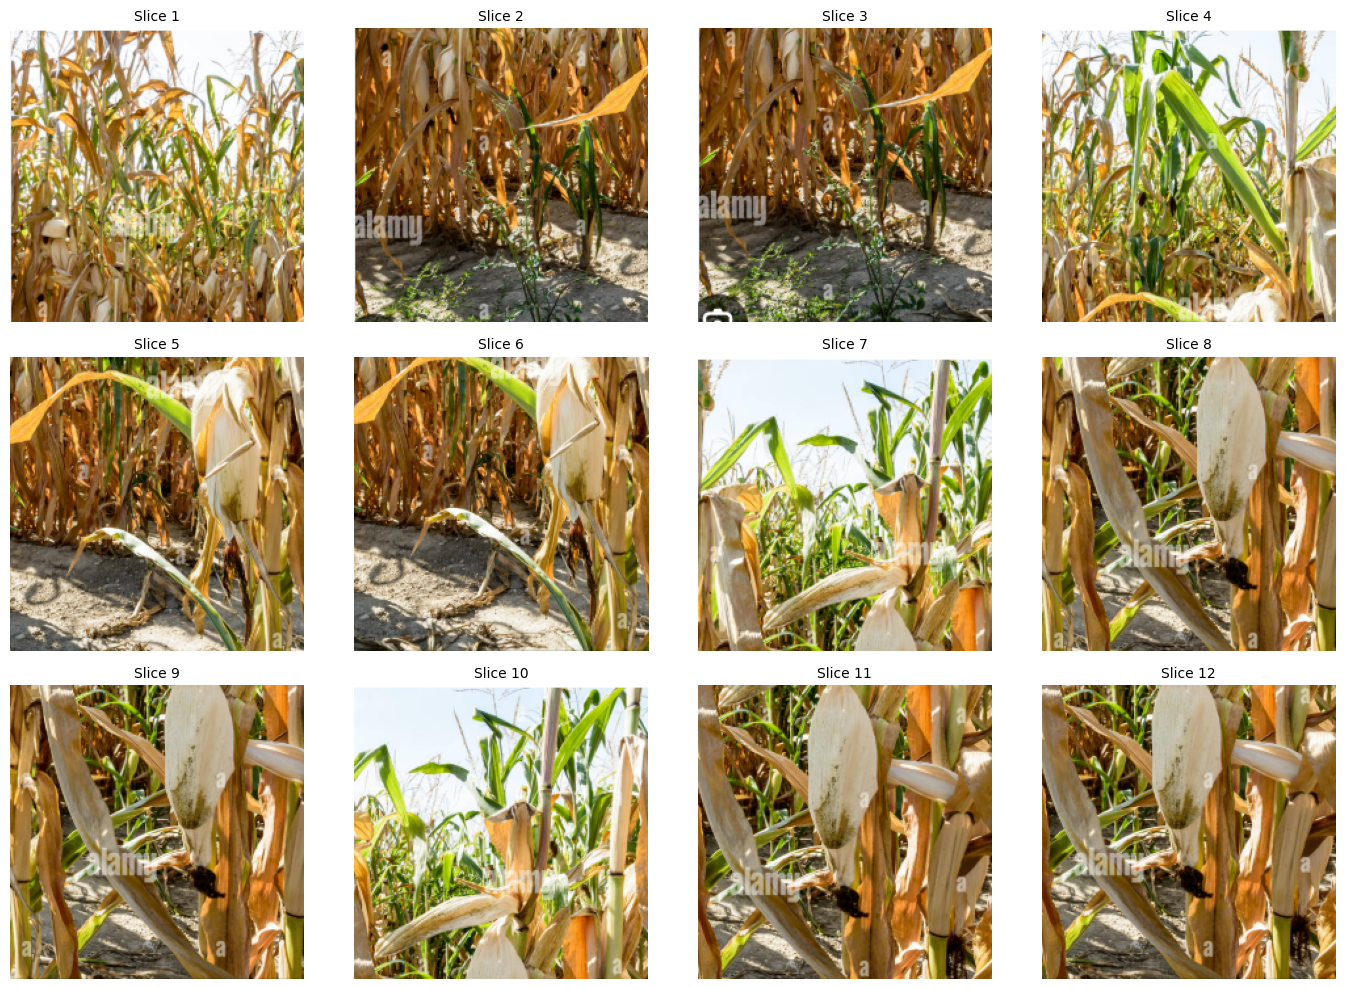

In [ ]:
import os
import matplotlib.pyplot as plt
from sahi.slicing import slice_image
from PIL import Image

image_path = "/content/Screenshot 2026-08-22 124123.png"  # 👈 Your image path
output_directory = "sahi_slices/"

# 1. Clear out old slices if you ran it before
if os.path.exists(output_directory):
    import shutil
    shutil.rmtree(output_directory)

# 2. Slice the image (SAHI saves these automatically to output_dir)
slice_image(
    image=image_path,
    output_file_name="slice",
    output_dir=output_directory,
    slice_height=224,
    slice_width=224,
    overlap_height_ratio=0.15,
    overlap_width_ratio=0.15
)

# 3. Grab the saved slices directly from the folder using standard Python 🚀
slice_files = [f for f in os.listdir(output_directory) if f.endswith(('.jpg', '.jpeg', '.png'))]
slice_files.sort()  # Sort them to keep them in order (slice_1, slice_2, etc.)
slice_paths = [os.path.join(output_directory, f) for f in slice_files]

# 4. Display the grid
num_slices = len(slice_paths)
print(f"Displaying all {num_slices} slices found in '{output_directory}':")

fig, axes = plt.subplots(3, 4, figsize=(14, 10))  # 3x4 layout for 12 slices
axes = axes.ravel()

for i, path in enumerate(slice_paths):
    img = Image.open(path)
    axes[i].imshow(img)
    axes[i].set_title(f"Slice {i+1}", fontsize=10)
    axes[i].axis('off')

# Hide any extra grid frames if the total slice count differs
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig("sahi_slice_grid_comparison.png", dpi=300)
plt.show()
